In [94]:
from pygments.util import duplicates_removed
github_url = "https://raw.githubusercontent.com/yatinderkoli/Indian-Car-Dataset/main/car_dataset_india.csv"

df = pd.read_csv(github_url)
#df = pd.read_csv(r"F:\project\car_dataset_india.csv")
print(df.head())

   Car_ID          Brand   Model  Year Fuel_Type Transmission      Price  \
0       1         Toyota  Innova  2024       CNG       Manual  2020000.0   
1       2            Kia     EV6  2023    Diesel       Manual  1770000.0   
2       3  Maruti Suzuki   Dzire  2016    Petrol       Manual  3430000.0   
3       4          Honda   Amaze  2019    Petrol       Manual  1610000.0   
4       5          Honda    City  2015  Electric       Manual  1840000.0   

   Mileage  Engine_CC  Seating_Capacity  Service_Cost  
0     27.3        800                 4       24100.0  
1     16.4       2500                 7       18800.0  
2     17.6       2000                 6       24700.0  
3     19.2       2500                 6       23300.0  
4     15.8       1000                 5        5800.0  


In [70]:
from textwrap import wrap

import  pandas as pd
from matplotlib import colors

from pygments.util import duplicates_removed

df = pd.read_csv(r"F:\project\car_dataset_india.csv")
print(df.head())

   Car_ID          Brand   Model  Year Fuel_Type Transmission      Price  \
0       1         Toyota  Innova  2024       CNG       Manual  2020000.0   
1       2            Kia     EV6  2023    Diesel       Manual  1770000.0   
2       3  Maruti Suzuki   Dzire  2016    Petrol       Manual  3430000.0   
3       4          Honda   Amaze  2019    Petrol       Manual  1610000.0   
4       5          Honda    City  2015  Electric       Manual  1840000.0   

   Mileage  Engine_CC  Seating_Capacity  Service_Cost  
0     27.3        800                 4       24100.0  
1     16.4       2500                 7       18800.0  
2     17.6       2000                 6       24700.0  
3     19.2       2500                 6       23300.0  
4     15.8       1000                 5        5800.0  


In [71]:
duplicates_count = df.duplicated().sum
print(f"Duplicate rows found and removed: {duplicates_count}")
df = df.drop_duplicates()
print(df)

Duplicate rows found and removed: <bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Length: 10000, dtype: bool>
      Car_ID          Brand          Model  Year Fuel_Type Transmission  \
0          1         Toyota         Innova  2024       CNG       Manual   
1          2            Kia            EV6  2023    Diesel       Manual   
2          3  Maruti Suzuki          Dzire  2016    Petrol       Manual   
3          4          Honda          Amaze  2019    Petrol       Manual   
4          5          Honda           City  2015  Electric       Manual   
...      ...            ...            ...   ...       ...          ...   
9995    9996    Tata Motors         Altroz  2021       CNG    Automatic   
9996    9997          Honda           WR-V  2024    Diesel    Automatic   
9997    9998       Mahindra         XUV300  2020  Electric       Manual   
9998  

In [72]:
#Handled Missing Data in Critical Columns
Missing_data = df.isnull().sum()
print(Missing_data)
Missing_data = df[['Price','Mileage']].isnull().sum()


Car_ID              0
Brand               0
Model               0
Year                0
Fuel_Type           0
Transmission        0
Price               0
Mileage             0
Engine_CC           0
Seating_Capacity    0
Service_Cost        0
dtype: int64


In [73]:
#Fill missing values with the median of that column
#df['Price']=df['Price'].fillna(df['Price']).mean()
#df['Mileage']=df['Mileage'].fillna(df['Mileage']).mean()
print(df)

      Car_ID          Brand          Model  Year Fuel_Type Transmission  \
0          1         Toyota         Innova  2024       CNG       Manual   
1          2            Kia            EV6  2023    Diesel       Manual   
2          3  Maruti Suzuki          Dzire  2016    Petrol       Manual   
3          4          Honda          Amaze  2019    Petrol       Manual   
4          5          Honda           City  2015  Electric       Manual   
...      ...            ...            ...   ...       ...          ...   
9995    9996    Tata Motors         Altroz  2021       CNG    Automatic   
9996    9997          Honda           WR-V  2024    Diesel    Automatic   
9997    9998       Mahindra         XUV300  2020  Electric       Manual   
9998    9999        Renault         Duster  2020    Diesel       Manual   
9999   10000         Toyota  Urban Cruiser  2018       CNG    Automatic   

          Price  Mileage  Engine_CC  Seating_Capacity  Service_Cost  
0     2020000.0     27.3     

In [74]:
import pandas as pd
from datetime import datetime

In [75]:
current_year = datetime.now().year
df['car_age'] = current_year -df['Year']
subset = df[['Brand','Model','Year','car_age']].head()
#print(df[['Brand','Model','Year','car_age']].head)
print(subset.to_markdown(index=False))

| Brand         | Model   |   Year |   car_age |
|:--------------|:--------|-------:|----------:|
| Toyota        | Innova  |   2024 |         2 |
| Kia           | EV6     |   2023 |         3 |
| Maruti Suzuki | Dzire   |   2016 |        10 |
| Honda         | Amaze   |   2019 |         7 |
| Honda         | City    |   2015 |        11 |


In [76]:
# 1. Check memory usage (in bytes) and dtypes BEFORE conversion

mem_before = df[['Fuel_Type', 'Transmission']].memory_usage(deep=True).drop('Index')
dtypes_before = df[['Fuel_Type', 'Transmission']].dtypes


In [77]:
# 2. Convert both columns to 'category' data type in one step
df[['Fuel_Type','Transmission']] = df[['Fuel_Type','Transmission']].astype('category')


In [78]:
# 3. Check memory usage and dtypes AFTER conversion
mem_after = df[['Fuel_Type','Transmission']].memory_usage(deep = True).drop('Index')
dtypes_after = df[['Fuel_Type','Transmission']].dtypes
print(mem_after,dtypes_after)

Fuel_Type       10219
Transmission    10113
dtype: int64 Fuel_Type       category
Transmission    category
dtype: object


In [79]:
#4 comparison summary table
comparison = pd.DataFrame({
    'Dtype (Before)':dtypes_before,
    'Dtype (after)':dtypes_after,
    'Memory (before)': mem_before,
    'Memory (after)': mem_after,
    'Memory Saved (%)':((mem_before - mem_after)/mem_before * 100).round(2)

})
print(comparison.to_markdown())

|              | Dtype (Before)   | Dtype (after)   |   Memory (before) |   Memory (after) |   Memory Saved (%) |
|:-------------|:-----------------|:----------------|------------------:|-----------------:|-------------------:|
| Fuel_Type    | str              | category        |            547272 |            10219 |              98.13 |
| Transmission | str              | category        |            564865 |            10113 |              98.21 |


In [80]:
family_cars = df[(df['Seating_Capacity'] >= 6) & (df['Price'] >= 1500000)]
print(f"Total Family Cars Found: {len(family_cars)} out of {len(df)} total cars\n")
cols_to_show = ['Car_ID', 'Brand', 'Model', 'Year', 'Seating_Capacity', 'Price', 'Fuel_Type']
print(df[cols_to_show].head().to_markdown (index=False, floatfmt=".0f"))

Total Family Cars Found: 3319 out of 10000 total cars

|   Car_ID | Brand         | Model   |   Year |   Seating_Capacity |   Price | Fuel_Type   |
|---------:|:--------------|:--------|-------:|-------------------:|--------:|:------------|
|        1 | Toyota        | Innova  |   2024 |                  4 | 2020000 | CNG         |
|        2 | Kia           | EV6     |   2023 |                  7 | 1770000 | Diesel      |
|        3 | Maruti Suzuki | Dzire   |   2016 |                  6 | 3430000 | Petrol      |
|        4 | Honda         | Amaze   |   2019 |                  6 | 1610000 | Petrol      |
|        5 | Honda         | City    |   2015 |                  5 | 1840000 | Electric    |


In [81]:
filtered_df = df[(df['Year'] >= 2019) & (df['Fuel_Type']=='Petrol') ]
a = ['Brand','Model','Year','Price']
print(filtered_df[a].head(10).to_markdown(index=False,floatfmt=".of"))

| Brand       | Model   |   Year |     Price |
|:------------|:--------|-------:|----------:|
| Honda       | Amaze   |   2019 | 1610000.0 |
| Kia         | Sonet   |   2020 | 2780000.0 |
| Renault     | Kiger   |   2022 |  820000.0 |
| Skoda       | Kushaq  |   2023 | 3360000.0 |
| Tata Motors | Punch   |   2024 | 2650000.0 |
| Honda       | Amaze   |   2022 |  960000.0 |
| Volkswagen  | Tiguan  |   2020 | 3160000.0 |
| Mahindra    | Bolero  |   2019 | 2480000.0 |
| Hyundai     | i10     |   2024 | 2830000.0 |
| Mahindra    | XUV300  |   2022 | 2150000.0 |


In [82]:
#Combine the Brand and Model columns into a single Full_Name
df['Price']=df['Price'].astype(int)
df['Full_Name'] = df['Brand'] + ' ' + df['Model']
cols = ['Car_ID', 'Brand', 'Model', 'Full_Name', 'Year', 'Price']
print(df[cols].head().to_markdown(index=False, floatfmt=".f"))

|   Car_ID | Brand         | Model   | Full_Name           |   Year |   Price |
|---------:|:--------------|:--------|:--------------------|-------:|--------:|
|        1 | Toyota        | Innova  | Toyota Innova       |   2024 | 2020000 |
|        2 | Kia           | EV6     | Kia EV6             |   2023 | 1770000 |
|        3 | Maruti Suzuki | Dzire   | Maruti Suzuki Dzire |   2016 | 3430000 |
|        4 | Honda         | Amaze   | Honda Amaze         |   2019 | 1610000 |
|        5 | Honda         | City    | Honda City          |   2015 | 1840000 |


In [83]:
# Top 5 Most Economical Cars):
#----------------------------------------
#Converted Price and Service_Cost to whole integers
df['Service_Cost'] = df['Service_Cost'].astype(int)

df['value_scores_per_km']=(df['Mileage']/df['Service_Cost']*1000).round(2)
#  Sort from highest to lowest Value_Score to find the most economical cars
top_economical = df.sort_values(by='value_scores_per_km',ascending=False)
#  top 5 most economical cars
cols = ['Car_ID', 'Brand', 'Model', 'Full_Name','value_scores_per_km']
print(top_economical[cols].head().to_markdown(index=False))

|   Car_ID | Brand         | Model   | Full_Name            |   value_scores_per_km |
|---------:|:--------------|:--------|:---------------------|----------------------:|
|     8764 | Mahindra      | XUV300  | Mahindra XUV300      |                  5.98 |
|     7269 | Hyundai       | Creta   | Hyundai Creta        |                  5.82 |
|     8287 | Skoda         | Slavia  | Skoda Slavia         |                  5.8  |
|     6797 | Maruti Suzuki | Baleno  | Maruti Suzuki Baleno |                  5.77 |
|     7811 | Hyundai       | Creta   | Hyundai Creta        |                  5.76 |


10
Unique brands in dataset: 10
| Brand         |   Listings Count |   Market Share (%) |
|:--------------|-----------------:|-------------------:|
| Maruti Suzuki |             1042 |              10.42 |
| Volkswagen    |             1034 |              10.34 |
| Hyundai       |             1033 |              10.33 |
| Mahindra      |             1024 |              10.24 |
| Skoda         |             1011 |              10.11 |
| Tata Motors   |              989 |               9.89 |
| Honda         |              982 |               9.82 |
| Kia           |              973 |               9.73 |
| Renault       |              958 |               9.58 |
| Toyota        |              954 |               9.54 |

Summary Stats of Brand Counts:
|       |   count |
|:------|--------:|
| count |   10    |
| mean  | 1000    |
| std   |   32.93 |
| min   |  954    |
| 25%   |  975.25 |
| 50%   | 1000    |
| 75%   | 1030.75 |
| max   | 1042    |


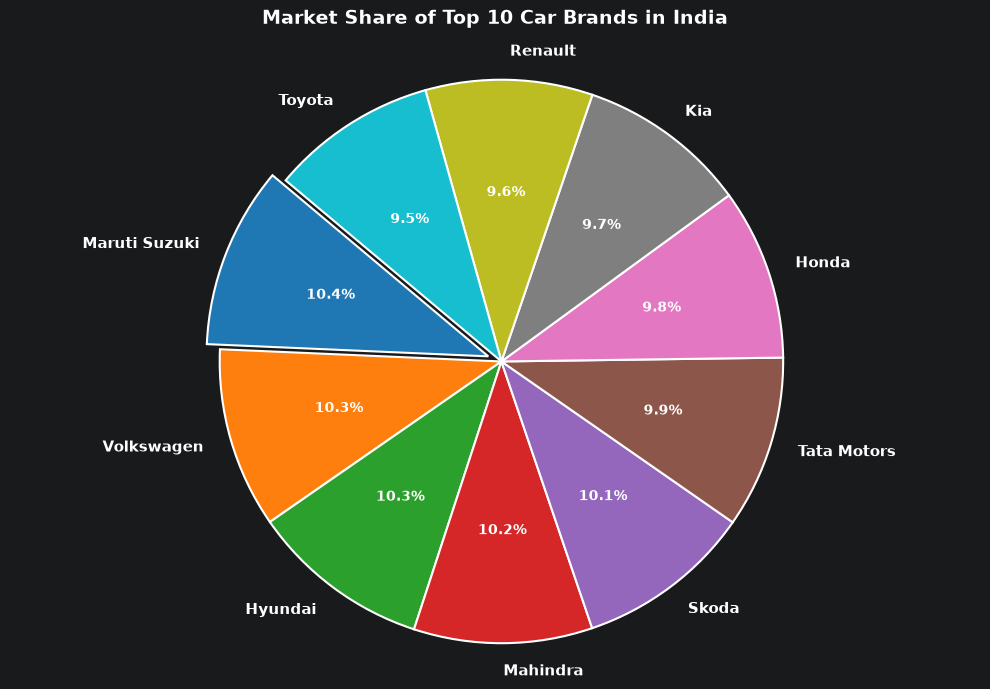

In [84]:
import matplotlib.pyplot as plt
import pandas as pd
brand_counts= df['Brand'].value_counts().head(10)
print(brand_counts.nunique())
print("Unique brands in dataset:", df['Brand'].nunique())
brand_df=pd.DataFrame({
    #'Brand':df['Brand'].uique(10)
     'Brand':brand_counts.index,
     'Listings Count': brand_counts.values,
     'Market Share (%)': (brand_counts.values / len(df) * 100).round(2)

})
print(brand_df.to_markdown(index=False))

print("\nSummary Stats of Brand Counts:")
print(brand_counts.describe().round(2).to_markdown())

# the Pie Chart Configured and ploted
plt.figure(figsize=(10,7))
colors=plt.cm.tab10.colors
explode = [0.05 if i == 0 else 0 for i in range(len(colors))]
wedges, texts, autotexts = plt.pie(
    brand_counts.values,
    labels=brand_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=explode,
    shadow=False,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.setp(autotexts, size=10, weight="bold", color="white")
plt.setp(texts, size=11, weight="bold")
plt.title("Market Share of Top 10 Car Brands in India", fontsize=14, weight="bold", pad=20)
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle
plt.tight_layout()
plt.savefig("brand_market_share_pie.png", dpi=300)
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_14548\301299381.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=11)


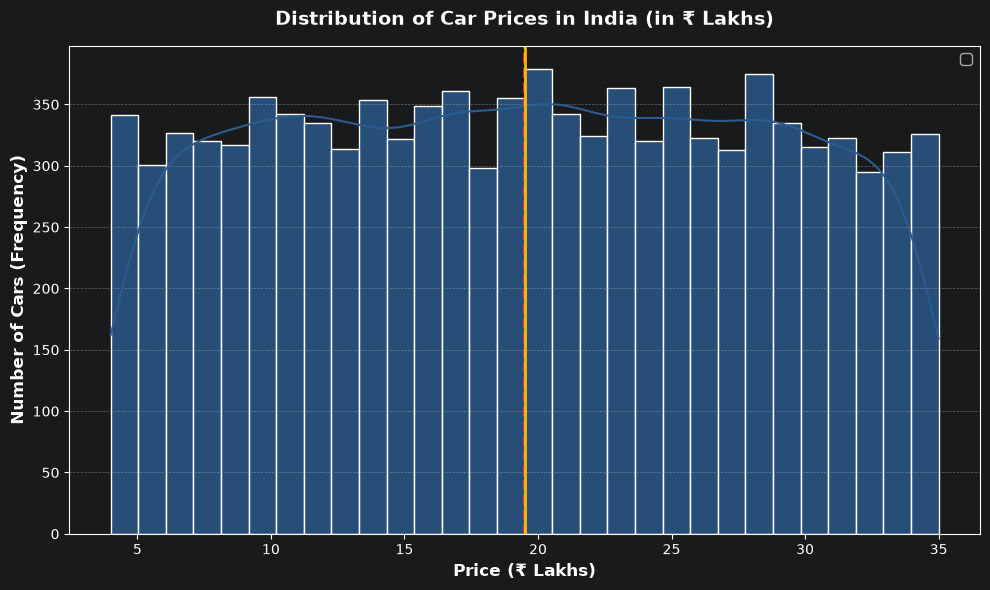

In [85]:

import seaborn as sns

#Converted  Price to Lakhs (₹1 Lakh = ₹100,000) for readable axis labels
df['Price_Lakhs'] = df['Price']/100000

# 3. Plot the Histogram
plt.figure(figsize=(10,6))
sns.histplot(
    df['Price_Lakhs'],
    bins=30,
    kde=True,
    color='#2b5c8f',
    edgecolor='white',  # Fixed spelling: 'edgecolor' (not 'egdecolor')
    alpha=0.8
)
# 4. Added vertical lines for Mean and Median to check for skewness
mean_value= df['Price_Lakhs'].mean()
median_value = df['Price_Lakhs'].median()

plt.axvline(mean_value, color='#e63946', linestyle='--', linewidth=2)
plt.axvline(median_value, color='#ffb703', linestyle='-', linewidth=2)

# 5. Add titles, labels, and grid
plt.title('Distribution of Car Prices in India (in ₹ Lakhs)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Price (₹ Lakhs)', fontsize=12, weight='bold')
plt.ylabel('Number of Cars (Frequency)', fontsize=12, weight='bold')
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Mileage Summary Statistics by Fuel Type:
| Fuel_Type   |   count |   mean |   std |   min |   25% |   50% |   75% |   max |
|:------------|--------:|-------:|------:|------:|------:|------:|------:|------:|
| CNG         |    2588 |  20.1  |  5.79 |    10 |  14.9 |  20.1 | 25.12 |    30 |
| Diesel      |    2468 |  20    |  5.75 |    10 |  14.9 |  20.2 | 24.8  |    30 |
| Electric    |    2518 |  19.85 |  5.77 |    10 |  14.9 |  19.7 | 24.8  |    30 |
| Petrol      |    2426 |  19.91 |  5.8  |    10 |  14.9 |  19.8 | 25    |    30 |


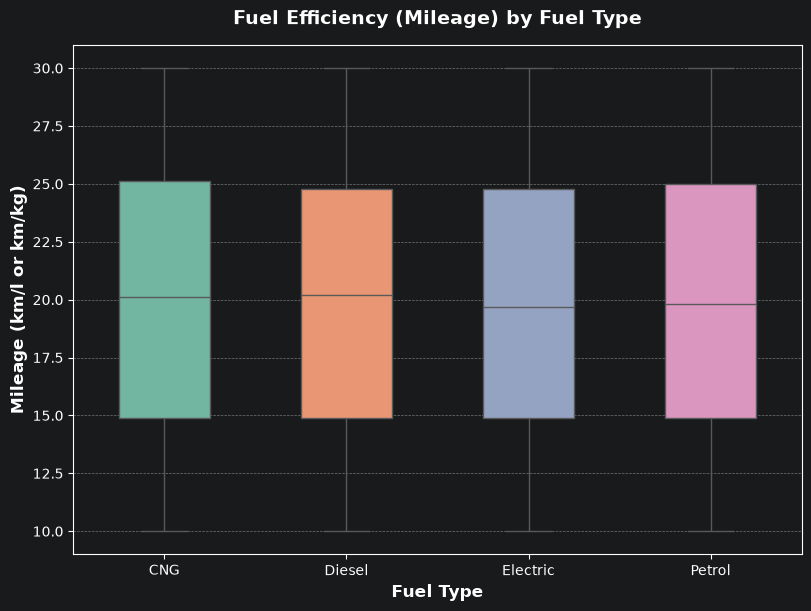

In [86]:
 #the Mileage spread across different Fuel_Type categories to see which fuel offers the most consistent efficiency
import seaborn as sns
mileage_stats= df.groupby('Fuel_Type')['Mileage'].describe().round(2)
#print(mileage_stats.to_markdown(index=True, floatfmt=".f"))
print("Mileage Summary Statistics by Fuel Type:")
print(mileage_stats.to_markdown())
plt.figure(figsize=(8,6), layout='constrained')
sns.boxplot(
    x='Fuel_Type',
    y='Mileage',
    hue='Fuel_Type',
    data=df,
    dodge=False,
    palette='Set2',
    width=0.5,
    legend=False)
plt.title('Fuel Efficiency (Mileage) by Fuel Type', fontsize=14, weight='bold', pad=15)
plt.xlabel('Fuel Type', fontsize=12, weight='bold')
plt.ylabel('Mileage (km/l or km/kg)', fontsize=12, weight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.6)
#plt.tight_layout(pad=1.0)
plt.savefig('fuel_efficiency_boxplot.png', dpi=300)
plt.show()

Summary Statistics for Engine_CC and Price:
|   Engine_CC |      Price |   Price_Lakhs |
|------------:|-----------:|--------------:|
|        8.0  |       8.0  |          8.0  |
|     2487.44 | 1571232.31 |       1265.7  |
|     3101.38 | 1177957.67 |       3529.2  |
|      557.49 |   10000.0  |          4.0  |
|      950.0  |  762845.88 |         11.06 |
|     1521.04 | 1563032.0  |         19.48 |
|     2125.0  | 2137500.0  |         29.0  |
|    10000.0  | 3500000.0  |      10000.0  |

Unique Engine_CC values: [np.int64(800), np.int64(1000), np.int64(1200), np.int64(1500), np.int64(1800), np.int64(2000), np.int64(2500)]

Price (in Lakhs) by Engine_CC:
|   Engine_CC |   count |   mean |   min |   max |
|------------:|--------:|-------:|------:|------:|
|         800 |    1454 |  19.41 |     4 |    35 |
|        1000 |    1422 |  19.64 |     4 |    35 |
|        1200 |    1430 |  19.72 |     4 |    35 |
|        1500 |    1421 |  19.47 |     4 |    35 |
|        1800 |    1410 |  19.

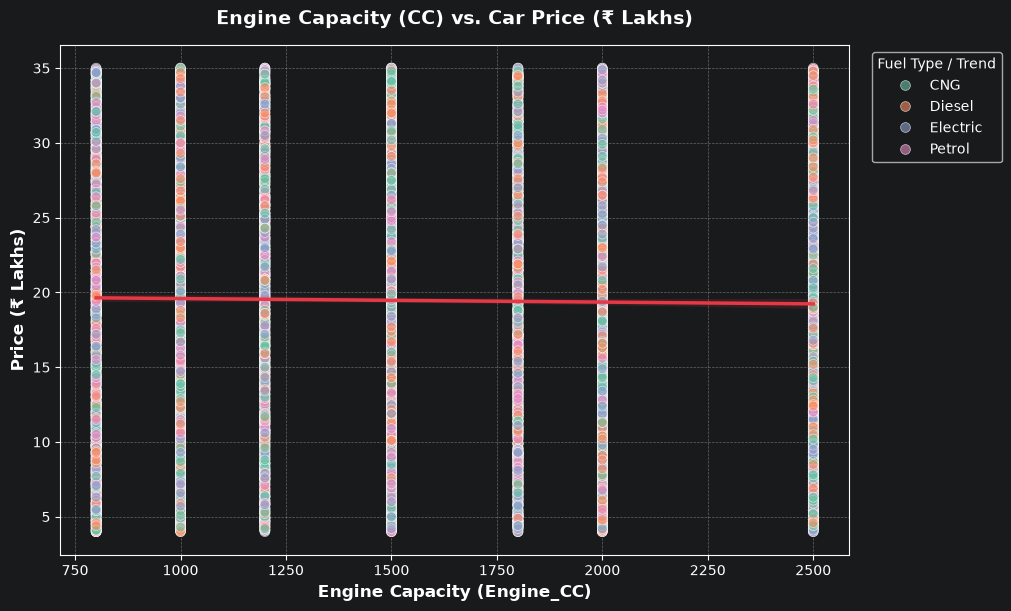

In [87]:
#Engine vs. Price :  Engine_CC against Price to visualize how engine size impacts the cost.

#statistics for Engine_CC and Price_Lakhs
print("Summary Statistics for Engine_CC and Price:")

stats = df[['Engine_CC', 'Price', 'Price_Lakhs']].describe().round(2)
#print(stats.to_markdown(index=False,))
print(stats.describe().round(2).to_markdown(index='False',floatfmt=".f"))
print("\nUnique Engine_CC values:", sorted(df['Engine_CC'].unique()))

# Mean/Median Price by Engine_CC
grouped=df.groupby('Engine_CC')['Price_Lakhs'].agg(['count','mean','min', 'max']).round(2)
print("\nPrice (in Lakhs) by Engine_CC:")
print(grouped.to_markdown())

# Correlation
corr = df['Engine_CC'].corr(df['Price'])
print(f"\nCorrelation between Engine_CC and Price: {corr:.4f}")



#Scatter Plot with Regression Trendline
plt.figure(figsize=(10, 6), layout='constrained')
sns.scatterplot(
    data=df,
    x='Engine_CC',
    y='Price_Lakhs',
    hue='Fuel_Type',
    palette='Set2',
    alpha=0.6,
    s=50
)

#mean price per Engine_CC to make the trend clear on discrete Engine_CC values
sns.regplot(
    data=df,
    x='Engine_CC',
    y='Price_Lakhs',
    scatter=False,
    color='#e63946',
    line_kws={'linewidth': 2.5, 'label': f'Trendline (r = {corr:.4f})'}
)
plt.title('Engine Capacity (CC) vs. Car Price (₹ Lakhs)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Engine Capacity (Engine_CC)', fontsize=12, weight='bold')
plt.ylabel('Price (₹ Lakhs)', fontsize=12, weight='bold')
plt.legend(title='Fuel Type / Trend', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('engine_vs_price_scatter.png', dpi=300)
plt.show()

Yearly Price Statistics (in Lakhs INR):
|   count |   mean |   min |   max |   median |
|--------:|-------:|------:|------:|---------:|
|   979.0 |  19.22 |   4.0 |  35.0 |    19.3  |
|   959.0 |  20.09 |   4.0 |  34.9 |    20.3  |
|  1017.0 |  19.11 |   4.1 |  35.0 |    18.6  |
|  1002.0 |  19.86 |   4.0 |  35.0 |    20.25 |
|  1004.0 |  19.18 |   4.0 |  35.0 |    19.05 |
|   991.0 |  18.75 |   4.0 |  35.0 |    18.1  |
|   985.0 |  20.01 |   4.0 |  35.0 |    20.6  |
|   981.0 |  19.68 |   4.0 |  35.0 |    20.0  |
|  1047.0 |  19.53 |   4.0 |  35.0 |    19.6  |
|  1035.0 |  19.21 |   4.0 |  35.0 |    19.2  |

Year Summary Statistics:
count    10000.00
mean      2019.54
std          2.88
min       2015.00
25%       2017.00
50%       2020.00
75%       2022.00
max       2024.00
Name: Year, dtype: float64


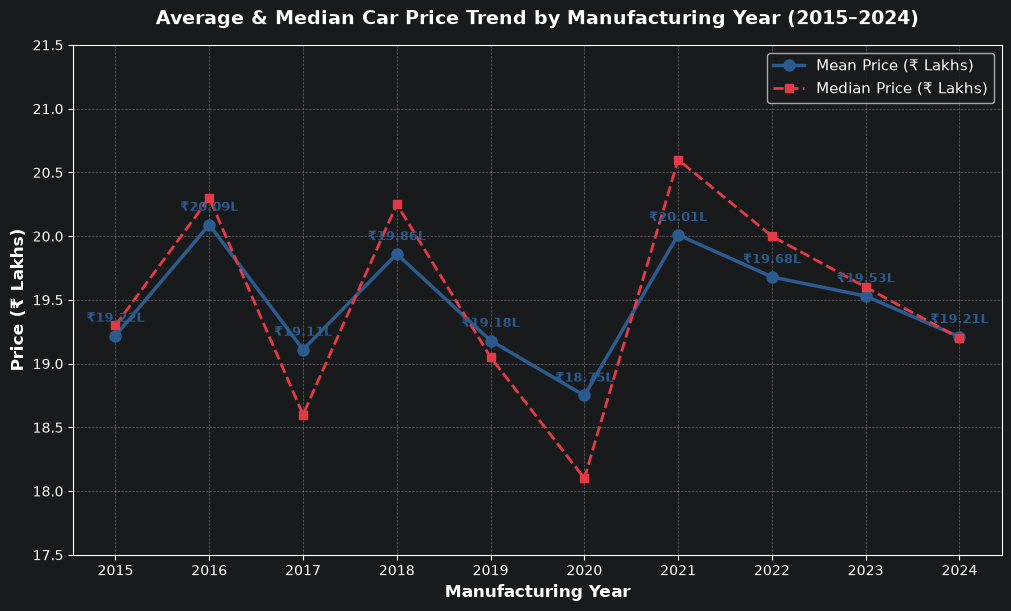

In [88]:
# Group the data by Year and plot the average Price to visualize inflation and depreciation trends.

# Group by Year and  summary statistics for Price_Lakhs calculated
yearly_stats = df.groupby('Year')['Price_Lakhs'].agg(['count','mean','min','max','median']).round(2)
print("Yearly Price Statistics (in Lakhs INR):")
print(yearly_stats.to_markdown(index='False',floatfmt=".f"))

# Overall summary stats for Year
print("\nYear Summary Statistics:")
print(df['Year'].describe().round(2))

# Plot the Line Chart
plt.figure(figsize=(10, 6), layout='constrained')

# Plot Mean and Median Price over time
plt.plot(
    yearly_stats.index,
    yearly_stats['mean'],
    marker='o',
    color='#2b5c8f',
    linewidth=2.5,
    markersize=8,
    label='Mean Price (₹ Lakhs)'
)

plt.plot(
    yearly_stats.index,
    yearly_stats['median'],
    marker='s',
    color='#e63946',
    linestyle='--',
    linewidth=2,
    markersize=6,
    label='Median Price (₹ Lakhs)'
)
# Add data labels for Mean Price on each point
for year, mean_val in zip(yearly_stats.index, yearly_stats['mean']):
    plt.annotate(
        f'₹{mean_val:.2f}L',
        (year, mean_val),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=9,
        weight='bold',
        color='#2b5c8f'
    )

plt.title('Average & Median Car Price Trend by Manufacturing Year (2015–2024)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Manufacturing Year', fontsize=12, weight='bold')
plt.ylabel('Price (₹ Lakhs)', fontsize=12, weight='bold')
plt.xticks(yearly_stats.index)
plt.ylim(17.5, 21.5)
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig('price_trend_by_year_line.png', dpi=300)
plt.show()




|              |   Price |   Mileage |   Engine_CC |   Service_Cost |
|:-------------|--------:|----------:|------------:|---------------:|
| Price        |  1      |    0.0128 |     -0.015  |         0.0023 |
| Mileage      |  0.0128 |    1      |      0.0004 |        -0.0138 |
| Engine_CC    | -0.015  |    0.0004 |      1      |         0.0132 |
| Service_Cost |  0.0023 |   -0.0138 |      0.0132 |         1      |


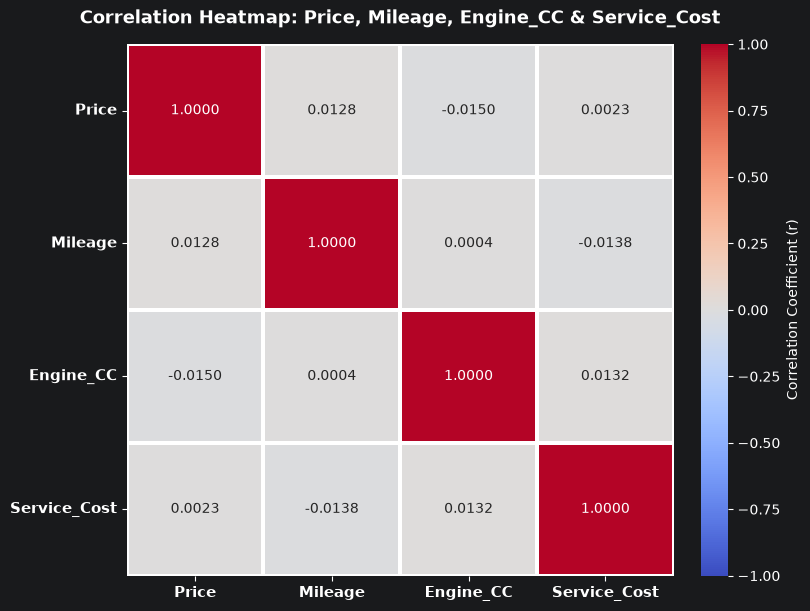

In [89]:
#Correlation Heatmap: relationship between Price, Mileage, Engine_CC, and Service_Cost.

cols =['Price','Mileage','Engine_CC','Service_Cost']
corr_matrix = df[cols].corr()
print(corr_matrix.round(4).to_markdown())


plt.figure(figsize=(8, 6), layout='constrained')

sns.heatmap(
    corr_matrix,
    annot=True,              # Display the exact correlation numbers inside each square
    fmt=".4f",               # Format numbers to 4 decimal places (captures tiny correlations)
    cmap='coolwarm',         # Blue for negative (-1), Red for positive (+1), Neutral in center (0)
    vmin=-1,                 # Lock color scale minimum to -1
    vmax=1,                  # Lock color scale maximum to +1
    center=0,                # Center the color palette at 0.0
    linewidths=1.5,          # Add clean spacing borders between grid cells
    linecolor='white',
    cbar_kws={'label': 'Correlation Coefficient (r)'}
)

# 4. Style titles and axis labels
plt.title('Correlation Heatmap: Price, Mileage, Engine_CC & Service_Cost', fontsize=13, weight='bold', pad=15)
plt.xticks(fontsize=11, weight='bold')
plt.yticks(fontsize=11, weight='bold', rotation=0)  # Keep y-axis labels horizontal for readability

plt.show()

|   Price_Lakhs |
|--------------:|
|       19.2176 |
|       20.0897 |
|       19.1127 |
|       19.8557 |
|       19.1826 |
|       18.7534 |
|       20.0055 |
|       19.6837 |
|       19.5317 |
|       19.2123 |


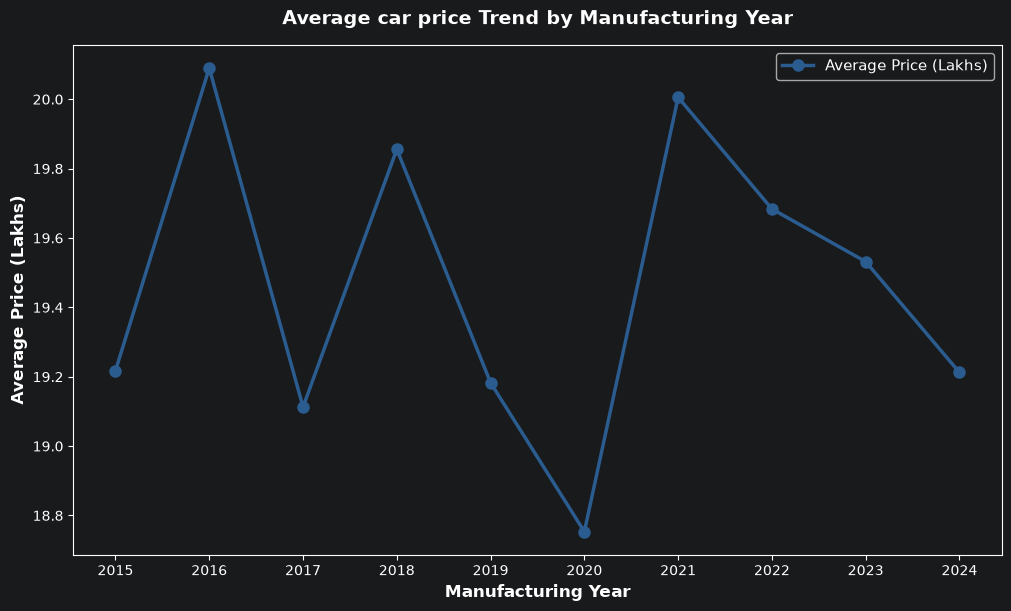

In [90]:
#TREND Over Time (Line Chart): Year and plot the average Price to visualize inflation and depreciation trends.
# gROUP BY YEAR AND THE AVERAGE PRICE CALCULATED

yearly_avg_price =df.groupby('Year')['Price_Lakhs'].mean()
print(yearly_avg_price.round(4).to_markdown(index='False',floatfmt='.f'))
#line chart configured
plt.figure(figsize=(10,6),layout='constrained')

plt.plot(
    yearly_avg_price.index,
    yearly_avg_price.values,
    marker='o',
    color='#2b5c8f',
    linewidth=2.5,
    markersize=8,
    label='Average Price (Lakhs)'
)
plt.title('Average car price Trend by Manufacturing Year', fontsize=14, weight='bold', pad=15)
plt.xlabel('Manufacturing Year', fontsize=12, weight='bold')
plt.ylabel('Average Price (Lakhs)', fontsize=12, weight='bold')

plt.xticks(yearly_avg_price.index)
plt.legend(fontsize=11)
plt.show()

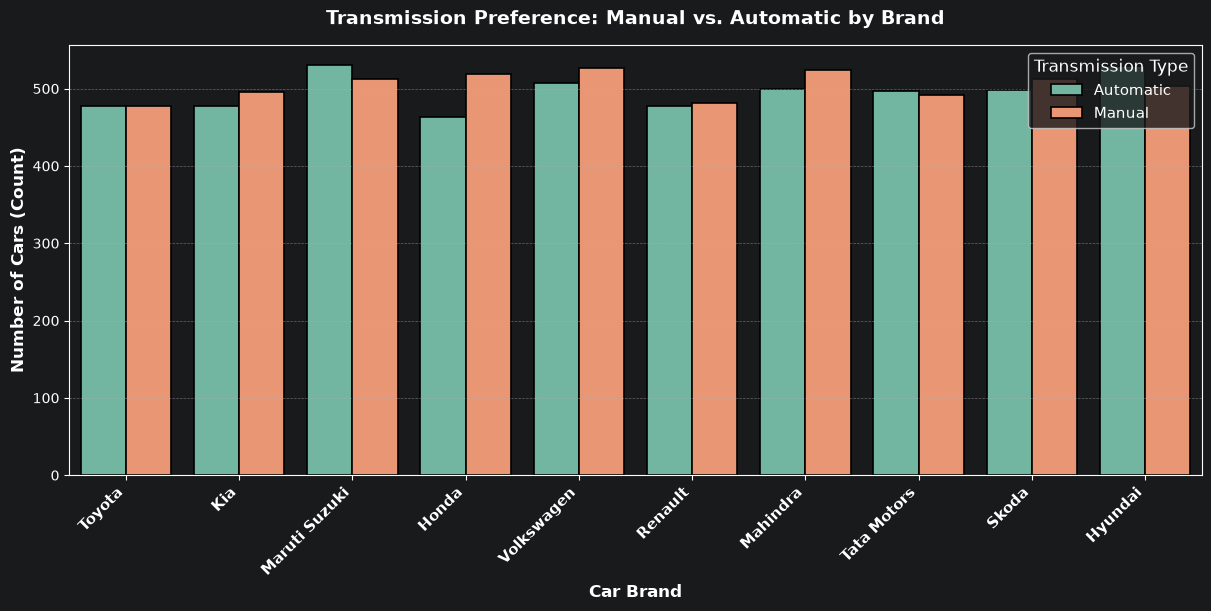

In [91]:

#Transmission Preference (Bar Chart):  the count of Manual vs. Automatic transmissions across different Brands

plt.figure(figsize=(12, 6), layout='constrained')


sns.countplot(
    data=df,
    x='Brand',
    hue='Transmission',
    palette='Set2',
    edgecolor='black',
    linewidth=1.2
)


plt.title('Transmission Preference: Manual vs. Automatic by Brand', fontsize=14, weight='bold', pad=15)
plt.xlabel('Car Brand', fontsize=12, weight='bold')
plt.ylabel('Number of Cars (Count)', fontsize=12, weight='bold')


plt.xticks(rotation=45, ha='right', fontsize=11, weight='bold')

plt.legend(title='Transmission Type', fontsize=11, title_fontsize=12, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [92]:
 # a new metric Value_Score by dividing Mileage by Service_Cost to find the most economical cars to run.
df['Price'] = df['Price'].astype(int)
df['Service_Cost'] = df['Service_Cost'].astype(int)

df['Value_Score'] = (df['Mileage'] / df['Service_Cost']).round(6)

df['Value_Score_Per_1k'] = ((df['Mileage'] / df['Service_Cost']) * 1000).round(2)
top_economical = df.sort_values(by='Value_Score', ascending=False)

cols = ['Car_ID', 'Brand', 'Model', 'Fuel_Type', 'Mileage', 'Service_Cost', 'Value_Score', 'Value_Score_Per_1k']
print("--- Top 5 Most Economical Cars to Run ---")
print(top_economical[cols].head(5).to_markdown(index=False,floatfmt= ".of",))

--- Top 5 Most Economical Cars to Run ---
|   Car_ID | Brand         | Model   | Fuel_Type   |   Mileage |   Service_Cost |   Value_Score |   Value_Score_Per_1k |
|---------:|:--------------|:--------|:------------|----------:|---------------:|--------------:|---------------------:|
|     8764 | Mahindra      | XUV300  | Petrol      |      29.9 |           5000 |      0.00598  |                 5.98 |
|     7269 | Hyundai       | Creta   | Electric    |      29.7 |           5100 |      0.005824 |                 5.82 |
|     8287 | Skoda         | Slavia  | Diesel      |      29.6 |           5100 |      0.005804 |                 5.8  |
|     6797 | Maruti Suzuki | Baleno  | CNG         |      30.0 |           5200 |      0.005769 |                 5.77 |
|     7811 | Hyundai       | Creta   | Diesel      |      29.4 |           5100 |      0.005765 |                 5.76 |


In [93]:
df['Q1']= df.groupby(['Model','Year'])['Price'].transform(lambda x: x.quantile(.25))
df['Q3'] = df.groupby(['Model','Year'])['Price'].transform(lambda x: x.quantile(.75))

df['IQR']= df['Q3'] - df['Q1']
df['Lower_bound'] = (df['Q1'] - 1.5 * df['IQR']).round(0)
df['Upper_bound'] = (df['Q3'] + 1.5 * df['IQR']).round(0)

outliers = df[(df['Price'] < df['Lower_bound']) | (df['Price'] > df['Upper_bound']) ]

print(f"Total Outliers Detected (1.5 * IQR Rule): {len(outliers)}")

cols = ['Car_ID', 'Brand', 'Model', 'Year', 'Price', 'Q1', 'Q3', 'Lower_bound', 'Upper_bound']

if len(outliers) > 0:
    print("\n--- Detected Price Outliers ---")
    print(outliers[cols].head(10).to_markdown(index=False))
else:
    print("\n--- Why 0 Outliers Were Found & Top 5 Most Extreme Cars by Group Deviation ---")
    df['Group_Median'] = df.groupby(['Model', 'Year'])['Price'].transform('median')
    df['Abs_Deviation'] = (df['Price'] - df['Group_Median']).abs()
    extreme_listings = df.sort_values(by='Abs_Deviation', ascending=False)
    print(extreme_listings[cols].head(5).to_markdown(index=False, floatfmt=".0f"))

Total Outliers Detected (1.5 * IQR Rule): 34

--- Detected Price Outliers ---
|   Car_ID | Brand       | Model   |   Year |   Price |              Q1 |         Q3 |      Lower_bound |   Upper_bound |
|---------:|:------------|:--------|-------:|--------:|----------------:|-----------:|-----------------:|--------------:|
|       42 | Tata Motors | Harrier |   2024 |  500000 |      2.04e+06   | 2.88e+06   |  780000          |   4.14e+06    |
|      171 | Mahindra    | XUV300  |   2021 |  430000 |      2.13e+06   | 2.9925e+06 |  836250          |   4.28625e+06 |
|      429 | Tata Motors | Punch   |   2021 | 2980000 | 982500          | 1.76e+06   | -183750          |   2.92625e+06 |
|      434 | Mahindra    | XUV300  |   2016 |  820000 |      2.1975e+06 | 3.0325e+06 |  945000          |   4.285e+06   |
|      812 | Toyota      | Innova  |   2020 |  610000 |      1.8075e+06 | 2.2475e+06 |       1.1475e+06 |   2.9075e+06  |
|     2597 | Hyundai     | Venue   |   2016 | 3460000 |      1.4425e